# 8. Data Tambahan (Sumber Kedua dan Ketiga)
Melengkapi data harga World Bank RTFP dengan dua sumber lain agar data bersifat multi-sumber:
1. **NASA POWER**: curah hujan dan suhu bulanan di koordinat tiap pasar (API, JSON).
2. **NOAA CPC**: Oceanic Nino Index (ONI) sebagai indikator El Nino dan La Nina (file teks).
3. **Kalender Ramadan dan Idulfitri** dihitung dengan kalender Hijriah tabular (turunan, bukan unduhan; selisih satu hari tidak berpengaruh karena dipakai per bulan).

Notebook ini perlu internet dan harus dijalankan di komputer sendiri. Pengambilan cuaca memakan beberapa menit; bila terputus, jalankan ulang karena pasar yang sudah terunduh dilewati.

In [1]:
import re

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, f1_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeClassifier

import os
import time
import requests
import matplotlib.pyplot as plt

data_path = '../data/processed/data_bersih.csv'
external_dir = '../data/external'
cuaca_path = f'{external_dir}/cuaca_bulanan.csv'
oni_path = f'{external_dir}/oni.csv'
kalender_path = f'{external_dir}/kalender_ramadan.csv'

NASA_URL = 'https://power.larc.nasa.gov/api/temporal/monthly/point'
ONI_URL = 'https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt'
TAHUN_AWAL = 2007
TAHUN_AKHIR = 2026

In [2]:
KOL_PASAR = 'mkt_name'
KOL_TANGGAL = 'date'
KOL_INDEKS = 'food_price_index'
KOMODITAS = ['eggs', 'garlic', 'meat_beef', 'meat_chicken', 'meat_chicken_broiler', 'oil', 'onions', 'rice', 'sugar']

BATAS_WASPADA = 5
BATAS_LONJAKAN = 10
NAMA_KELAS = ['Normal', 'Waspada', 'Lonjakan']
FITUR_DASAR = ['inflasi_ini', 'inflasi_lalu', 'bulan']
PERSEN_TEST = 0.2
TAHUN_ACUAN_AKHIR = 2019

BOBOT_RISIKO = 0.6
BOBOT_MOMENTUM = 0.2
BOBOT_VOLATILITAS = 0.2
BATAS_PRIORITAS = 50
BATAS_PANTAU = 25
BATAS_HARGA_PERSEN = 5

NAMA_KOMODITAS = {
    'eggs': 'Telur', 'garlic': 'Bawang Putih', 'meat_beef': 'Daging Sapi', 'meat_chicken': 'Daging Ayam',
    'meat_chicken_broiler': 'Daging Ayam Broiler', 'oil': 'Minyak Goreng', 'onions': 'Bawang Merah',
    'rice': 'Beras', 'sugar': 'Gula', 'food_price_index': 'Indeks Pangan',
}
MUSIM_ONI = ['DJF', 'JFM', 'FMA', 'MAM', 'AMJ', 'MJJ', 'JJA', 'JAS', 'ASO', 'SON', 'OND', 'NDJ']

In [3]:
def tambah_rentang(d):
    h, l, c = f'h_{KOL_INDEKS}', f'l_{KOL_INDEKS}', f'c_{KOL_INDEKS}'
    if {h, l, c}.issubset(d.columns):
        return (d[h] - d[l]) / d[c] * 100
    return pd.Series(np.nan, index=d.index)


def siapkan_fitur(df):
    kol_inf = f'inflation_{KOL_INDEKS}'
    d = df.sort_values([KOL_PASAR, KOL_TANGGAL]).reset_index(drop=True)
    g = d.groupby(KOL_PASAR)
    out = pd.DataFrame({KOL_PASAR: d[KOL_PASAR], KOL_TANGGAL: d[KOL_TANGGAL]})
    out['inflasi_ini'] = d[kol_inf]
    out['inflasi_lalu'] = g[kol_inf].shift(1)
    out['inflasi_depan'] = g[kol_inf].shift(-1)
    out['bulan'] = d[KOL_TANGGAL].dt.month
    for k in KOMODITAS:
        if f'inflation_{k}' in d.columns:
            out[f'inf_{k}'] = d[f'inflation_{k}']
    if f'trust_{KOL_INDEKS}' in d.columns:
        out['trust_indeks'] = d[f'trust_{KOL_INDEKS}']
    for k in KOMODITAS:
        if f'trust_{k}' in d.columns:
            out[f'trust_{k}'] = d[f'trust_{k}']
    rentang = tambah_rentang(d)
    if rentang.notna().any():
        out['rentang_harga'] = rentang
    if 'spatially_interpolated' in d.columns:
        out['interpolasi'] = pd.to_numeric(d['spatially_interpolated'], errors='coerce')
    mentah = [k for k in KOMODITAS if k in d.columns]
    if mentah:
        ada_survei = (d[mentah].notna().sum(axis=1) > 0).astype(float)
        out['obs_12b'] = ada_survei.groupby(d[KOL_PASAR]).transform(lambda x: x.rolling(12, min_periods=1).sum())
    periode = d[KOL_TANGGAL].dt.to_period('M')
    out['lalu_ok'] = g[KOL_TANGGAL].shift(1).dt.to_period('M') == periode - 1
    out['depan_ok'] = g[KOL_TANGGAL].shift(-1).dt.to_period('M') == periode + 1
    return out


def parse_cuaca_nasa(data, nama_pasar):
    p = data['properties']['parameter']
    baris = []
    for kunci, hujan in p['PRECTOTCORR'].items():
        if kunci.endswith('13'):
            continue
        suhu = p['T2M'].get(kunci)
        baris.append({KOL_PASAR: nama_pasar, 'bulan': pd.Timestamp(int(kunci[:4]), int(kunci[4:]), 1),
                      'hujan': np.nan if hujan <= -990 else hujan, 'suhu': np.nan if suhu is None or suhu <= -990 else suhu})
    return pd.DataFrame(baris)


def parse_oni(teks):
    baris = []
    for garis in teks.splitlines():
        bagian = garis.split()
        if len(bagian) >= 4 and bagian[0] in MUSIM_ONI and bagian[1].isdigit():
            baris.append({'bulan': pd.Timestamp(int(bagian[1]), MUSIM_ONI.index(bagian[0]) + 1, 1), 'oni': float(bagian[-1])})
    return pd.DataFrame(baris)


def hijriah_ke_masehi(tahun, bulan, hari):
    jd = hari + np.ceil(29.5 * (bulan - 1)) + (tahun - 1) * 354 + (3 + 11 * tahun) // 30 + 1948439.5 - 1
    return pd.Timestamp.fromordinal(int(jd - 2451544.5 + 730120))


def kalender_ramadan(tahun_awal=2006, tahun_akhir=2028):
    bulan_ramadan, bulan_idulfitri = set(), set()
    for th in range(1420, 1455):
        awal, akhir = hijriah_ke_masehi(th, 9, 1), hijriah_ke_masehi(th, 10, 1)
        for hari in pd.date_range(awal, akhir - pd.Timedelta(days=1)):
            bulan_ramadan.add((hari.year, hari.month))
        bulan_idulfitri.add((akhir.year, akhir.month))
    bulan = pd.date_range(f'{tahun_awal}-01-01', f'{tahun_akhir}-12-01', freq='MS')
    return pd.DataFrame({'bulan': bulan,
                         'ramadan_ada': [int((b.year, b.month) in bulan_ramadan) for b in bulan],
                         'idulfitri_ada': [int((b.year, b.month) in bulan_idulfitri) for b in bulan]})


def tambah_fitur_eksternal(out, cuaca=None, oni=None):
    out = out.copy()
    out['_bulan'] = out[KOL_TANGGAL].dt.to_period('M').dt.to_timestamp()
    if cuaca is not None and len(cuaca):
        c = cuaca.copy()
        c['bulan'] = pd.to_datetime(c['bulan'])
        c = c.sort_values([KOL_PASAR, 'bulan']).reset_index(drop=True)
        c['bln'] = c['bulan'].dt.month
        acuan = c[c['bulan'].dt.year <= TAHUN_ACUAN_AKHIR]
        normal = acuan.groupby([KOL_PASAR, 'bln'])[['hujan', 'suhu']].mean().rename(columns={'hujan': 'hujan_normal', 'suhu': 'suhu_normal'})
        c = c.join(normal, on=[KOL_PASAR, 'bln'])
        c['anom_hujan_ini'] = c['hujan'] - c['hujan_normal']
        c['anom_suhu_ini'] = c['suhu'] - c['suhu_normal']
        g = c.groupby(KOL_PASAR)
        c['anom_hujan_lag1'] = g['anom_hujan_ini'].shift(1)
        c['anom_hujan_lag2'] = g['anom_hujan_ini'].shift(2)
        c['anom_suhu_lag1'] = g['anom_suhu_ini'].shift(1)
        c = c.rename(columns={'hujan': 'hujan_ini', 'suhu': 'suhu_ini', 'bulan': '_bulan'})
        kolom = [KOL_PASAR, '_bulan', 'hujan_ini', 'suhu_ini', 'anom_hujan_ini', 'anom_hujan_lag1', 'anom_hujan_lag2', 'anom_suhu_ini', 'anom_suhu_lag1']
        out = out.merge(c[kolom], on=[KOL_PASAR, '_bulan'], how='left')
    if oni is not None and len(oni):
        o = oni.copy()
        o['_bulan'] = pd.to_datetime(o['bulan'])
        o = o.sort_values('_bulan').reset_index(drop=True)
        o['oni_ini'] = o['oni']
        o['oni_lag3'] = o['oni'].shift(3)
        out = out.merge(o[['_bulan', 'oni_ini', 'oni_lag3']], on='_bulan', how='left')
    kal = kalender_ramadan(out['_bulan'].dt.year.min() - 1, out['_bulan'].dt.year.max() + 1).set_index('bulan')
    depan = out['_bulan'] + pd.offsets.MonthBegin(1)
    out['ramadan_ini'] = out['_bulan'].map(kal['ramadan_ada']).values
    out['ramadan_depan'] = depan.map(kal['ramadan_ada']).values
    out['idulfitri_ini'] = out['_bulan'].map(kal['idulfitri_ada']).values
    out['idulfitri_depan'] = depan.map(kal['idulfitri_ada']).values
    return out.drop(columns='_bulan')


def daftar_fitur_eksternal(out):
    return [c for c in out.columns if c.startswith(('hujan_', 'suhu_', 'anom_', 'oni_', 'ramadan_', 'idulfitri_'))]

## Daftar pasar dan koordinat

In [4]:
df = pd.read_csv(data_path, parse_dates=[KOL_TANGGAL])
pasar = df.drop_duplicates(KOL_PASAR)[[KOL_PASAR, 'lat', 'lon']].reset_index(drop=True)
os.makedirs(external_dir, exist_ok=True)
print(f'{len(pasar)} pasar, periode {df[KOL_TANGGAL].min():%b %Y} sampai {df[KOL_TANGGAL].max():%b %Y}')

222 pasar, periode Jan 2007 sampai Aug 2026


## Sumber kedua: cuaca NASA POWER
Parameter PRECTOTCORR (curah hujan terkoreksi, mm per hari) dan T2M (suhu 2 meter, derajat Celsius), rata-rata bulanan.

In [5]:
def ambil_cuaca(nama, lat, lon):
    params = {'parameters': 'PRECTOTCORR,T2M', 'community': 'AG', 'latitude': lat, 'longitude': lon,
              'start': TAHUN_AWAL, 'end': TAHUN_AKHIR, 'format': 'JSON'}
    for percobaan in range(3):
        try:
            r = requests.get(NASA_URL, params=params, timeout=90)
            r.raise_for_status()
            return parse_cuaca_nasa(r.json(), nama)
        except Exception as e:
            print(f'  {nama}: percobaan {percobaan + 1} gagal ({e})')
            time.sleep(3)
    return None

sudah = pd.read_csv(cuaca_path, parse_dates=['bulan']) if os.path.exists(cuaca_path) else pd.DataFrame(columns=[KOL_PASAR, 'bulan', 'hujan', 'suhu'])
hasil = [sudah]
selesai = set(sudah[KOL_PASAR])
for i, r in pasar.iterrows():
    if r[KOL_PASAR] in selesai:
        continue
    d = ambil_cuaca(r[KOL_PASAR], r['lat'], r['lon'])
    if d is not None:
        hasil.append(d)
    if (i + 1) % 20 == 0:
        pd.concat(hasil).to_csv(cuaca_path, index=False)
        print(f'{i + 1} dari {len(pasar)} pasar')
    time.sleep(0.5)
cuaca = pd.concat([h for h in hasil if len(h)], ignore_index=True)
cuaca['bulan'] = pd.to_datetime(cuaca['bulan'])
cuaca.to_csv(cuaca_path, index=False)
print(f'Cuaca tersimpan: {cuaca[KOL_PASAR].nunique()} dari {len(pasar)} pasar, {len(cuaca):,} baris')

Cuaca tersimpan: 222 dari 222 pasar, 53,058 baris


In [6]:
kosong = sorted(set(pasar[KOL_PASAR]) - set(cuaca[KOL_PASAR]))
print('Pasar tanpa data cuaca:', kosong if kosong else 'tidak ada')
cuaca.describe().round(2)

Pasar tanpa data cuaca: tidak ada


,bulan,hujan,suhu
count,53058,52614.00,52614.00
mean,2016-11-30 11:44:56.234309888,6.97,25.97
min,2007-01-01 00:00:00,0.00,11.90
25%,2011-12-01 00:00:00,3.65,25.07
50%,2016-12-01 00:00:00,6.57,26.19
75%,2021-12-01 00:00:00,9.51,27.22
max,2026-11-01 00:00:00,133.76,31.05
std,NaN,5.20,1.98


## Sumber ketiga: indeks ENSO (ONI) dari NOAA
ONI adalah anomali suhu laut rata-rata tiga bulan di Pasifik tengah. Nilai di atas 0,5 menandakan El Nino (cenderung lebih kering di Indonesia) dan di bawah -0,5 La Nina (cenderung lebih basah).

In [7]:
r = requests.get(ONI_URL, timeout=60)
r.raise_for_status()
oni = parse_oni(r.text)
oni = oni[(oni['bulan'].dt.year >= TAHUN_AWAL) & (oni['bulan'].dt.year <= TAHUN_AKHIR)]
oni.to_csv(oni_path, index=False)
print(f'ONI tersimpan: {len(oni)} bulan, {oni["bulan"].min():%b %Y} sampai {oni["bulan"].max():%b %Y}')
oni.tail()

ONI tersimpan: 237 bulan, Jan 2007 sampai Sep 2026


,bulan,oni
916,2026-05-01,0.95
917,2026-06-01,1.39
918,2026-07-01,1.80
919,2026-08-01,2.16
920,2026-09-01,2.46


## Kalender Ramadan dan Idulfitri

In [8]:
kalender = kalender_ramadan(TAHUN_AWAL, TAHUN_AKHIR + 1)
kalender.to_csv(kalender_path, index=False)
kalender[(kalender['ramadan_ada'] == 1) | (kalender['idulfitri_ada'] == 1)].tail(6)

,bulan,ramadan_ada,idulfitri_ada
207,2024-04-01,1,1
218,2025-03-01,1,1
229,2026-02-01,1,0
230,2026-03-01,1,1
241,2027-02-01,1,0
242,2027-03-01,1,1


## Memahami sumber tambahan
Seberapa besar hubungan fitur eksternal dengan inflasi indeks pangan bulan depan? Korelasi dihitung per pasar lalu diambil mediannya.

In [9]:
out = tambah_fitur_eksternal(siapkan_fitur(df), cuaca, oni)
fitur_eks = daftar_fitur_eksternal(out)
kol_depan = 'inflasi_depan'
korelasi = out.groupby(KOL_PASAR).apply(lambda g: g[fitur_eks + [kol_depan]].corr()[kol_depan].drop(kol_depan))
ringkas = pd.DataFrame({'korelasi_median': korelasi.median(), 'persen_pasar_positif': (korelasi > 0).mean() * 100}).round(3).rename_axis('fitur')
ringkas.sort_values('korelasi_median')

C:\Users\Administrator\AppData\Local\Temp\ipykernel_8324\2678666138.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  korelasi = out.groupby(KOL_PASAR).apply(lambda g: g[fitur_eks + [kol_depan]].corr()[kol_depan].drop(kol_depan))


,korelasi_median,persen_pasar_positif
fitur,,
oni_lag3,-0.124,2.252
anom_suhu_ini,-0.102,2.252
anom_suhu_lag1,-0.097,2.252
suhu_ini,-0.065,3.153
anom_hujan_ini,-0.040,30.180
oni_ini,-0.039,28.378
anom_hujan_lag1,-0.022,40.541
hujan_ini,-0.019,34.685
anom_hujan_lag2,-0.013,39.640


Korelasi yang mendekati nol berarti fitur itu hampir tidak menjelaskan inflasi bulan depan secara linear. Itu hasil yang sah dan dilaporkan apa adanya. Seberapa besar sumbangannya terhadap klasifikasi diuji di notebook 5.

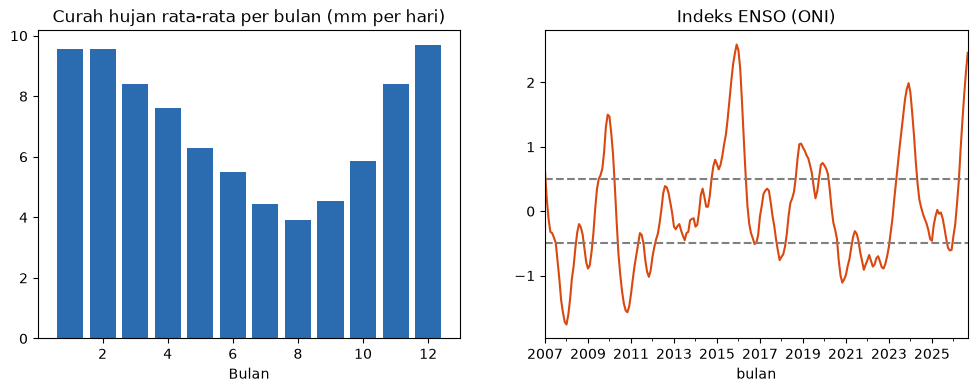

In [10]:
bulan_rata = cuaca.assign(bln=cuaca['bulan'].dt.month).groupby('bln')[['hujan', 'suhu']].mean()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(bulan_rata.index, bulan_rata['hujan'], color='#2b6cb0')
ax[0].set_title('Curah hujan rata-rata per bulan (mm per hari)')
ax[0].set_xlabel('Bulan')
oni.set_index('bulan')['oni'].plot(ax=ax[1], color='#d9480f', title='Indeks ENSO (ONI)')
ax[1].axhline(0.5, color='gray', linestyle='dashed')
ax[1].axhline(-0.5, color='gray', linestyle='dashed')
plt.show()